In [1]:
from google.colab import userdata

try:
    token = userdata.get('KAGGLE_API_TOKEN')
    if token:
        print(f"SUCCESS: Secret read successfully! Starts with: {token[:8]}...")
    else:
        print("FAIL: Key exists in Secrets, but its Value field is empty.")
except Exception as e:
    print(f"ERROR: Could not access secret -> {e}")

SUCCESS: Secret read successfully! Starts with: KGAT_ef6...


In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# Search for any public dataset containing "jane street real-time"
!kaggle datasets list -s "jane street real-time market data"

ref                                                         title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
mohamedsameh0410/jane-street-dataset                        Jane Street Real-Time Market Data Forecasting      12300796839  2025-01-19 11:24:44.753000           1525         43                1  
jtrotman/jane-street-real-time-market-data-forecasting-lbs  Jane Street Real-Time Market Data Forecasting LBs      2244287  2025-07-19 11:31:03.190000             49          0            0.875  
hideyukizushi/jsridgev01011635                              JS|Ridge|v01011635                                        1631  2025-01-02 01:26:54.500000             65          2           0.3125  
hideyukizushi/als-e-

In [3]:
!kaggle datasets files -d daniilvolkov/js24-fits-ram


name                        size  creationDate                
--------------------  ----------  --------------------------  
partition_id=0.pkl     456897421  2024-11-09 11:20:17.365000  
partition_id=1.pkl     574878715  2024-11-09 11:20:21.776000  
partition_id=2.pkl     622567045  2024-11-09 11:20:23.549000  
partition_id=3.pkl     727045941  2024-11-09 11:20:28.400000  
partition_id=4.pkl     909162349  2024-11-09 11:20:35.778000  
partition_id=5.pkl     968032237  2024-11-09 11:20:37.786000  
partition_id=6.pkl    1122916109  2024-11-09 11:20:43.690000  
partition_id=7.pkl    1146744397  2024-11-09 11:20:44.964000  
partition_id=8.pkl    1111352381  2024-11-09 11:20:43.991000  
partition_id=9.pkl    1135706293  2024-11-09 11:20:44.863000  
partition_id=all.pkl  8530056215  2024-11-09 11:25:16.628000  


In [4]:
# CELL 1: FULL DATASET INGESTION & FORMAT CONVERSION
# Downloads partition chunks from Kaggle, unpacks pickle archives, and converts
# them into Apache Parquet format (columnar storage) for faster lazy loading
# and lower RAM consumption via Polars.
# Ref: Apache Parquet: https://en.wikipedia.org/wiki/Apache_Parquet
!pip install -q polars pyarrow seaborn matplotlib scikit-learn

import os
import gc
import pickle
import pandas as pd
import polars as pl
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# Setup staging directory for downloaded artifacts
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)
!rm -rf /content/data/*

# Partitions 8 and 9 selected for an out-of-sample temporal window
PARTITIONS_TO_LOAD = range(8, 10)

for pid in PARTITIONS_TO_LOAD:
    target_file = f"partition_id={pid}.pkl"
    out_parquet = f"{DATA_DIR}/part-{pid}.parquet"

    print(f"\n--- [{pid}/9] Letöltés: {target_file} (~1.1 GB) ---")
    !kaggle datasets download -d daniilvolkov/js24-fits-ram -f {target_file} -p {DATA_DIR}

    zip_path = f"{DATA_DIR}/{target_file}.zip"
    pkl_path = f"{DATA_DIR}/{target_file}"

    # Extract archive if compressed
    if os.path.exists(zip_path):
        !unzip -q -o {zip_path} -d {DATA_DIR}
        !rm -f {zip_path}

    print(f"[{pid}] Konvertálás Parquet formátumba...")
    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    # Standardize data structure to Polars DataFrame for fast disk writes
    if isinstance(data, pd.DataFrame):
        df = pl.from_pandas(data)
    elif isinstance(data, pl.DataFrame):
        df = data
    else:
        df = pl.DataFrame(data)

    # Save to Parquet and purge raw pickle to minimize disk/memory usage
    df.write_parquet(out_parquet)
    os.remove(pkl_path)

    print(f"[{pid}] KÉSZ: {df.shape[0]:,} sor elmentve ide: {out_parquet}")

    # Trigger garbage collection to reclaim memory between batches
    del data, df
    gc.collect()

# Lazy evaluation scan across all generated parquet partitions
PARQUET_FILE = f"{DATA_DIR}/part-*.parquet"
total_rows = pl.scan_parquet(PARQUET_FILE).select(pl.len()).collect().item()
print(f"\n=======================================================")
print(f"SIKER! A TELJES ADATKÉSZLET KÉSZEN ÁLL.")
print(f"Összes sor száma a memóriában/lemezen: {total_rows:,}")
print(f"=======================================================")


--- [8/9] Letöltés: partition_id=8.pkl (~1.1 GB) ---
Dataset URL: https://www.kaggle.com/datasets/daniilvolkov/js24-fits-ram
License(s): apache-2.0
100% 1.04G/1.04G [01:12<00:00, 15.2MB/s]

[8] Konvertálás Parquet formátumba...
[8] KÉSZ: 6,140,024 sor elmentve ide: /content/data/part-8.parquet

--- [9/9] Letöltés: partition_id=9.pkl (~1.1 GB) ---
Dataset URL: https://www.kaggle.com/datasets/daniilvolkov/js24-fits-ram
License(s): apache-2.0
100% 1.06G/1.06G [01:17<00:00, 14.7MB/s]

[9] Konvertálás Parquet formátumba...
[9] KÉSZ: 6,274,576 sor elmentve ide: /content/data/part-9.parquet

SIKER! A TELJES ADATKÉSZLET KÉSZEN ÁLL.
Összes sor száma a memóriában/lemezen: 12,414,600


Sampled DataFrame Shape: (12414600, 20)
Trading Days span: 1360 to 1698
Unique Assets (symbol_id): 39

--- Quantitative Market Statistics (responder_6) ---
Expected Mean (Center):       -0.001247
Volatility (Std Deviation):  0.828840
Skewness (Asymmetry):         0.7112
Excess Kurtosis (Fat Tails):  7.4212
99% Value-at-Risk (VaR):     -2.2422


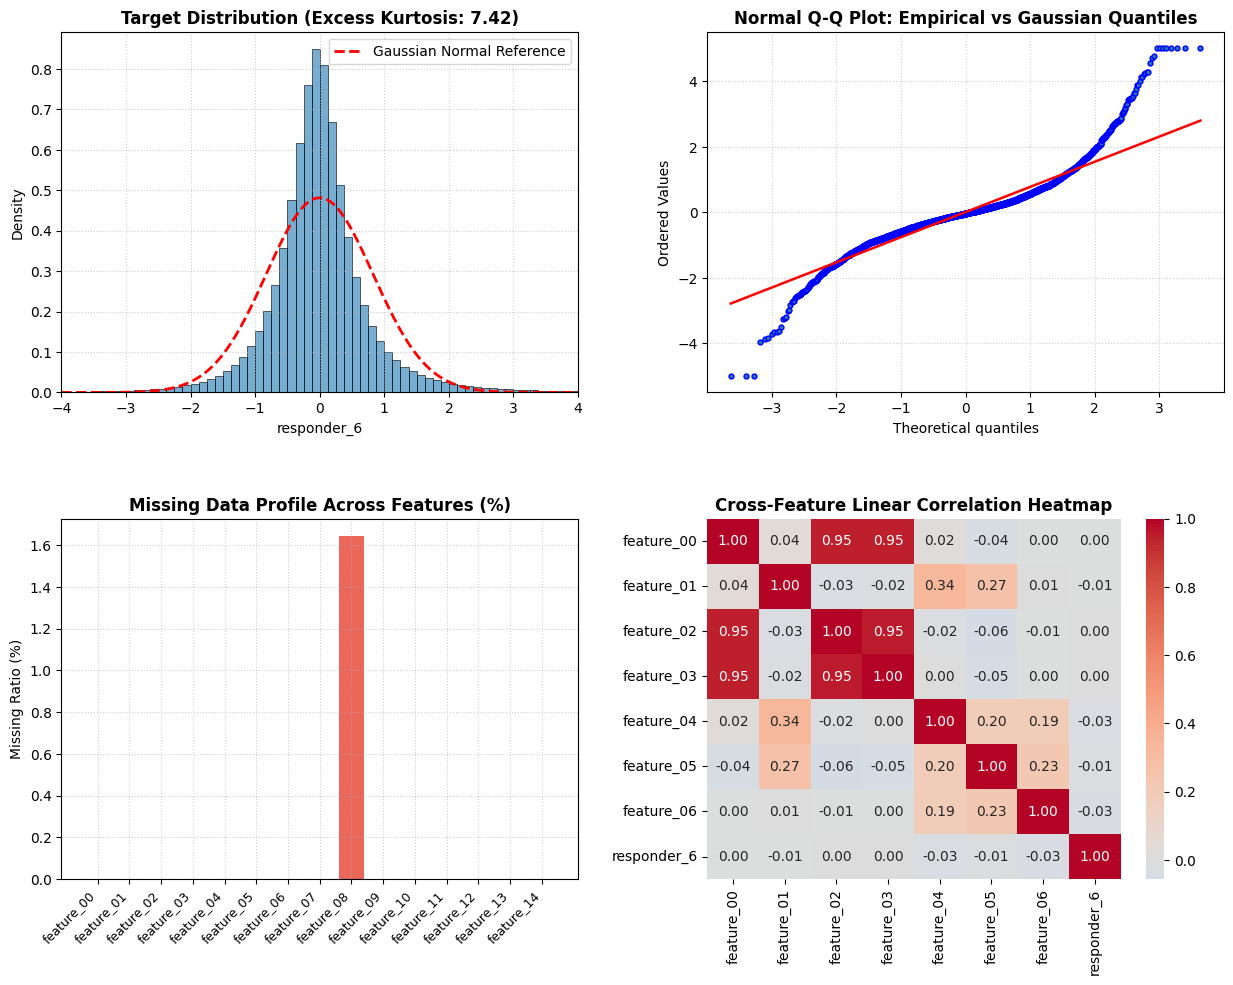

In [5]:

# CELL 2: DATA EXPLORATION, QUANTITATIVE STATISTICS & VISUALIZATION
# Milestone Point 2: Exploratory Data Analysis & Visualizations
# Computes core higher-order moments and risk metrics on financial returns.

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PARQUET_FILE = "/content/data/part-*.parquet"


# Load temporal identifiers, symbol tags, sample weights, target return (responder_6), and base features
cols_to_load = ["date_id", "time_id", "symbol_id", "weight", "responder_6"] + [f"feature_{i:02d}" for i in range(15)]

# 'upcast' float types to prevent Float32/Float64 mismatch across partitions
lf = pl.scan_parquet(PARQUET_FILE, cast_options=pl.ScanCastOptions(float_cast="upcast"))
df_raw = (
    lf.select(cols_to_load)
    .collect()
    .to_pandas()
    .sort_values(["date_id", "time_id", "symbol_id"])
    .reset_index(drop=True)
)

print(f"Sampled DataFrame Shape: {df_raw.shape}")
print(f"Trading Days span: {df_raw['date_id'].min()} to {df_raw['date_id'].max()}")
print(f"Unique Assets (symbol_id): {df_raw['symbol_id'].nunique()}")

# 2. Quantitative Finance Statistical Diagnostics
# Computes financial risk and return distribution metrics:
# - Expected Value (Mean): Central location of forward returns.
#   https://en.wikipedia.org/wiki/Expected_value
# - Volatility (Standard Deviation): Asset risk metric / dispersion of returns.
#   https://en.wikipedia.org/wiki/Volatility_(finance)
# - Skewness (3rd standardized moment): Return asymmetry (gain vs loss tail bias).
#   https://en.wikipedia.org/wiki/Skewness
# - Excess Kurtosis (4th standardized moment): Fat tails / leptokurtosis relative to normal.
#   https://en.wikipedia.org/wiki/Kurtosis
# - Value at Risk (VaR 99%): Maximum expected loss at 99% confidence over the interval.
#   https://en.wikipedia.org/wiki/Value_at_risk
r6 = df_raw["responder_6"].dropna()
mean_val = float(r6.mean())
std_val = float(r6.std())
skew_val = float(stats.skew(r6))
kurt_val = float(stats.kurtosis(r6, fisher=True)) # Fisher=True gives excess kurtosis (Normal = 0.0)
var_99 = float(np.percentile(r6, 1.0)) # 1st empirical percentile representing 99% VaR

print("\n--- Quantitative Market Statistics (responder_6) ---")
print(f"Expected Mean (Center):       {mean_val:.6f}")
print(f"Volatility (Std Deviation):  {std_val:.6f}")
print(f"Skewness (Asymmetry):         {skew_val:.4f}")
print(f"Excess Kurtosis (Fat Tails):  {kurt_val:.4f}")
print(f"99% Value-at-Risk (VaR):     {var_99:.4f}")

# 3. Quantitative Visualizations (4-Panel Dashboard)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Plot 1: Empirical density vs. Gaussian reference curve
sns.histplot(r6, bins=80, stat="density", color="#1f77b4", alpha=0.6, ax=axes[0, 0])
x_axis = np.linspace(-4, 4, 200)
axes[0, 0].plot(x_axis, stats.norm.pdf(x_axis, mean_val, std_val), "r--", lw=2, label="Gaussian Normal Reference")
axes[0, 0].set_xlim(-4, 4)
axes[0, 0].set_title(f"Target Distribution (Excess Kurtosis: {kurt_val:.2f})", fontweight="bold")
axes[0, 0].set_xlabel("responder_6")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Quantile-Quantile (Q-Q) Plot to visually inspect fat tails vs. Gaussian
# Ref: https://en.wikipedia.org/wiki/Q%E2%80%93Q_plot
stats.probplot(r6.sample(n=min(5000, len(r6)), random_state=42), dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_markerfacecolor("#1f77b4")
axes[0, 1].get_lines()[0].set_markersize(3.5)
axes[0, 1].get_lines()[1].set_color("red")
axes[0, 1].get_lines()[1].set_linewidth(1.8)
axes[0, 1].set_title("Normal Q-Q Plot: Empirical vs Gaussian Quantiles", fontweight="bold")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# Plot 3: Missing data profile across input features (for imputation audit)
feature_cols = [f"feature_{i:02d}" for i in range(15)]
missing_pct = df_raw[feature_cols].isna().mean() * 100
axes[1, 0].bar(range(len(feature_cols)), missing_pct.values, color="#e74c3c", alpha=0.85)
axes[1, 0].set_xticks(range(len(feature_cols)))
axes[1, 0].set_xticklabels(feature_cols, rotation=45, ha="right", fontsize=9)
axes[1, 0].set_title("Missing Data Profile Across Features (%)", fontweight="bold")
axes[1, 0].set_ylabel("Missing Ratio (%)")
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

# Plot 4: Pearson linear correlation matrix between initial features and target
# Ref: https://en.wikipedia.org/wiki/Pearson_correlation_coefficient
corr_mat = df_raw[feature_cols[:7] + ["responder_6"]].corr()
sns.heatmap(corr_mat, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1, 1], cbar=True)
axes[1, 1].set_title("Cross-Feature Linear Correlation Heatmap", fontweight="bold")

plt.show()

In [6]:
# CELL 3: DATA PREPARATION & CHRONOLOGICAL TRAIN / VAL / TEST SPLIT
# Milestone Point 3: Data preparation, resulting in Train, Val, Test splits
# Implements causal cross-sectional de-meaning, categorical encoding,
# chronological partitioning, and train-only robust scaling (IQR / median).
import pandas as pd
import keras

print("Executing causal quantitative engineering & chronological splitting...")

# 1. Feature Engineering: Cross-Sectional Relative Demeaning
# Computes asset-specific relative alpha vs. instantaneous market average at tick (date, time).
# Removes the broad market beta/drift, isolating idiosyncratic asset momentum.
# Ref: https://en.wikipedia.org/wiki/Cross-sectional_regression
cs_cols = ["feature_00", "feature_01", "feature_02"]
for c in cs_cols:
    market_mean = df_raw.groupby(["date_id", "time_id"])[c].transform("mean")
    df_raw[f"{c}_rel_mkt"] = (df_raw[c] - market_mean).fillna(0.0).astype(np.float32)

all_input_features = feature_cols + [f"{c}_rel_mkt" for c in cs_cols]

# 2. Map symbol_id to contiguous zero-indexed integers for Keras Embedding layer
unique_symbols = np.sort(df_raw["symbol_id"].unique())
symbol_map = {sym: idx for idx, sym in enumerate(unique_symbols)}
df_raw["symbol_idx"] = df_raw["symbol_id"].map(symbol_map).astype(np.int32)
num_unique_symbols = len(unique_symbols)

# 3. Chronological Split Boundaries (Zero look-ahead leakage)
# Time-series splits must be strictly sequential to avoid look-ahead bias.
# Ref: https://en.wikipedia.org/wiki/Data_leakage
# Train: First 70% of unique trading days | Val: Next 15% | Test: Most recent 15%
unique_dates = np.sort(df_raw["date_id"].unique())
n_dates = len(unique_dates)

train_cutoff = unique_dates[int(n_dates * 0.70)]
val_cutoff = unique_dates[int(n_dates * 0.85)]

train_mask = df_raw["date_id"] <= train_cutoff
val_mask = (df_raw["date_id"] > train_cutoff) & (df_raw["date_id"] <= val_cutoff)
test_mask = df_raw["date_id"] > val_cutoff

print(f"Date Splits -> Train: <= {train_cutoff} | Val: {train_cutoff + 1} to {val_cutoff} | Test: > {val_cutoff}")

# 4. Strictly Causal Scaling & Robust Imputation
# Parameters are derived exclusively from the TRAIN split to prevent forward-looking leakage.
# Uses Median Imputation and Interquartile Range (IQR) scaling (Robust Scaler) to resist outliers.
# Outliers are clipped (Winsorized) to [-5, 5].
# Ref: https://en.wikipedia.org/wiki/Interquartile_range
# Ref: https://en.wikipedia.org/wiki/Winsorizing
train_feats = df_raw.loc[train_mask, all_input_features].to_numpy(dtype=np.float32)
train_medians = np.nanmedian(train_feats, axis=0)
q75 = np.nanpercentile(train_feats, 75, axis=0)
q25 = np.nanpercentile(train_feats, 25, axis=0)
train_iqr = np.where((q75 - q25) > 1e-6, (q75 - q25), 1.0)

def prepare_split_arrays(mask):
    """Applies train-derived median imputation and IQR scaling, returning inputs & outputs."""
    sub_df = df_raw.loc[mask]

    # Continuous features: Imputed with train medians, scaled by train IQR, and clipped to [-5, 5]
    raw_x = sub_df[all_input_features].to_numpy(dtype=np.float32)
    imputed_x = np.where(np.isnan(raw_x), train_medians, raw_x)
    scaled_x = np.clip((imputed_x - train_medians) / train_iqr, -5.0, 5.0).astype(np.float32)

    # Categorical symbol indices (for entity embedding)
    symbols = sub_df["symbol_idx"].to_numpy(dtype=np.int32).reshape(-1, 1)

    # Target responses and competition sample weights
    y = sub_df["responder_6"].to_numpy(dtype=np.float32).reshape(-1, 1)
    weights = sub_df["weight"].to_numpy(dtype=np.float32).reshape(-1, 1)

    return [scaled_x, symbols], y, weights

# Build tensor input arrays for each chronological partition
X_train, y_train, w_train = prepare_split_arrays(train_mask)
X_val, y_val, w_val = prepare_split_arrays(val_mask)
X_test, y_test, w_test = prepare_split_arrays(test_mask)

# 5. Output Verification
print("\n--- Final Milestone Splits Ready for Model Training ---")
print(f"Train Set -> Continuous: {X_train[0].shape}, Symbol: {X_train[1].shape}, Y: {y_train.shape}, Weights: {w_train.shape}")
print(f"Val Set   -> Continuous: {X_val[0].shape}, Symbol: {X_val[1].shape}, Y: {y_val.shape}, Weights: {w_val.shape}")
print(f"Test Set  -> Continuous: {X_test[0].shape}, Symbol: {X_test[1].shape}, Y: {y_test.shape}, Weights: {w_test.shape}")
print(f"Total Unique Assets Encoded: {num_unique_symbols}")
print(f"Number of Continuous Features: {len(all_input_features)}")
print("\nAll arrays are formatted as float32/int32 and ready for multi-input Keras 3 model training.")

Executing causal quantitative engineering & chronological splitting...
Date Splits -> Train: <= 1597 | Val: 1598 to 1648 | Test: > 1648

--- Final Milestone Splits Ready for Model Training ---
Train Set -> Continuous: (8660696, 18), Symbol: (8660696, 1), Y: (8660696, 1), Weights: (8660696, 1)
Val Set   -> Continuous: (1883728, 18), Symbol: (1883728, 1), Y: (1883728, 1), Weights: (1883728, 1)
Test Set  -> Continuous: (1870176, 18), Symbol: (1870176, 1), Y: (1870176, 1), Weights: (1870176, 1)
Total Unique Assets Encoded: 39
Number of Continuous Features: 18

All arrays are formatted as float32/int32 and ready for multi-input Keras 3 model training.


Constructing Model: 18 Continuous Inputs | 39 Symbol IDs (Embedding Dim: 9)


Model: "JaneStreet_MultiInput_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ continuous_features │ (None, 18)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 18)        │         72 │ continuous_featu… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      2,432 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ symbol_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ symbol_embedding    │ (None, 1, 9)      │        351 │ symbol_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 9)         │          0 │ symbol_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 73)        │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,736 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ responder_6_pred    │ (None, 1)         │         33 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,216 (71.16 KB)

 Trainable params: 18,052 (70.52 KB)

 Non-trainable params: 164 (656.00 B)

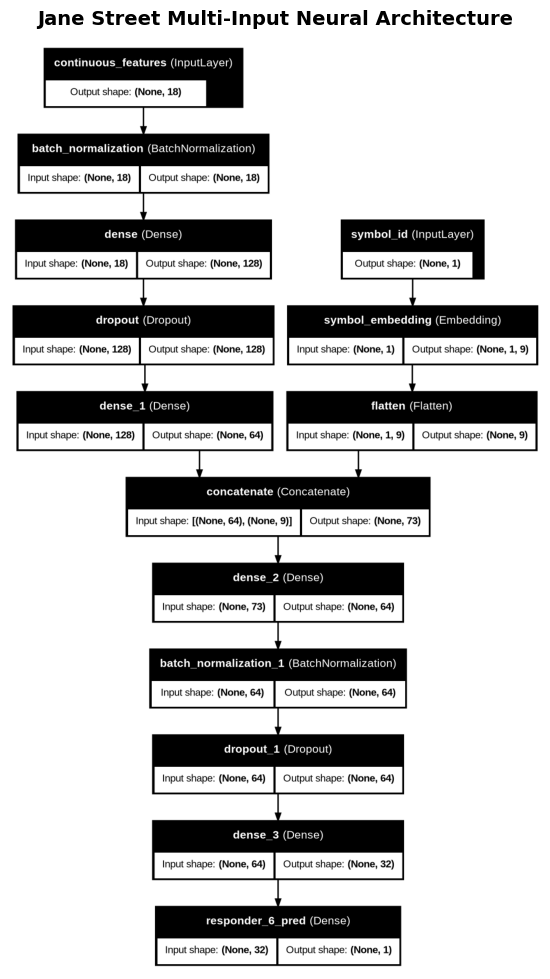

In [7]:

# CELL 4: MULTI-INPUT DEEP LEARNING ARCHITECTURE & VISUALIZATION# CELL 4: MULTI-INPUT DEEP LEARNING ARCHITECTURE & VISUALIZATION
# Multi-Input Architecture:
# - Input Branch A: Continuous microstructure & relative momentum signals (Dense + Swish + BN)
# - Input Branch B: Categorical asset identifier via learnable Entity Embedding
#   Ref: Entity Embeddings: https://en.wikipedia.org/wiki/Word_embedding
import keras
from keras import layers, ops
import matplotlib.pyplot as plt

# 1. Dimension Setup
n_continuous = X_train[0].shape[1]
n_symbols = num_unique_symbols
embedding_dim = min(16, max(4, n_symbols // 4))

print(f"Constructing Model: {n_continuous} Continuous Inputs | {n_symbols} Symbol IDs (Embedding Dim: {embedding_dim})")

# 2. Functional Architecture
# Input Branch A: Continuous features normalized via Batch Normalization
# Swish activation: f(x) = x * sigmoid(beta * x), smooth non-monotonic activation
input_continuous = layers.Input(shape=(n_continuous,), name="continuous_features")
x_cont = layers.BatchNormalization()(input_continuous)
x_cont = layers.Dense(128, activation="swish")(x_cont)
x_cont = layers.Dropout(0.2)(x_cont)
x_cont = layers.Dense(64, activation="swish")(x_cont)

# Input Branch B: Categorical asset embedding mapping discrete symbols to a dense space
input_symbol = layers.Input(shape=(1,), dtype="int32", name="symbol_id")
x_sym = layers.Embedding(input_dim=n_symbols, output_dim=embedding_dim, name="symbol_embedding")(input_symbol)
x_sym = layers.Flatten()(x_sym)

# Feature Fusion: Concatenates continuous signal representations with learned asset embeddings
merged = layers.concatenate([x_cont, x_sym])
x = layers.Dense(64, activation="swish")(merged)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="swish")(x)

# Output Layer: Single linear neuron predicting continuous normalized return (responder_6)
output_return = layers.Dense(1, activation="linear", name="responder_6_pred")(x)

# Instantiate multi-input Keras functional model
model = keras.Model(inputs=[input_continuous, input_symbol], outputs=output_return, name="JaneStreet_MultiInput_Net")

# 3. Model Compilation
# Optimizer: AdamW (Adam with decoupled weight decay for regularized generalization)
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss="mse",
    metrics=["mae", "root_mean_squared_error"],
    weighted_metrics=[]
)

model.summary()

# 4. Architecture Graph Visualization
try:
    keras.utils.plot_model(
        model,
        to_file="model_architecture.png",
        show_shapes=True,
        show_layer_names=True,
        dpi=96
    )
    img = plt.imread("model_architecture.png")
    plt.figure(figsize=(10, 12))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Jane Street Multi-Input Neural Architecture", fontsize=14, fontweight="bold", pad=15)
    plt.show()
except Exception as e:
    print(f"Graphviz plot skipped ({e}); structural summary printed above.")